In [1]:
from google.colab import drive
drive.mount('/content/drive')
import os
imgpath = '/content/drive/MyDrive/의료영상처리'
#os.listdir(imgpath)

Mounted at /content/drive


In [2]:
import nibabel as nib
import matplotlib.pyplot as plt

## Exercise 0. day0, day15, reg에 대해 display하여 비교

In [4]:
ct_base = nib.load(imgpath + '/ITK/volume-covid19-A-0700_day000.nii.gz').get_fdata()
ct_FU = nib.load(imgpath + '/ITK/volume-covid19-A-0700_day015.nii.gz').get_fdata()
ct_FU_reg = nib.load(imgpath + '/ITK/volume-covid19-A-0700_day015-reg_to_day000.nii.gz').get_fdata()

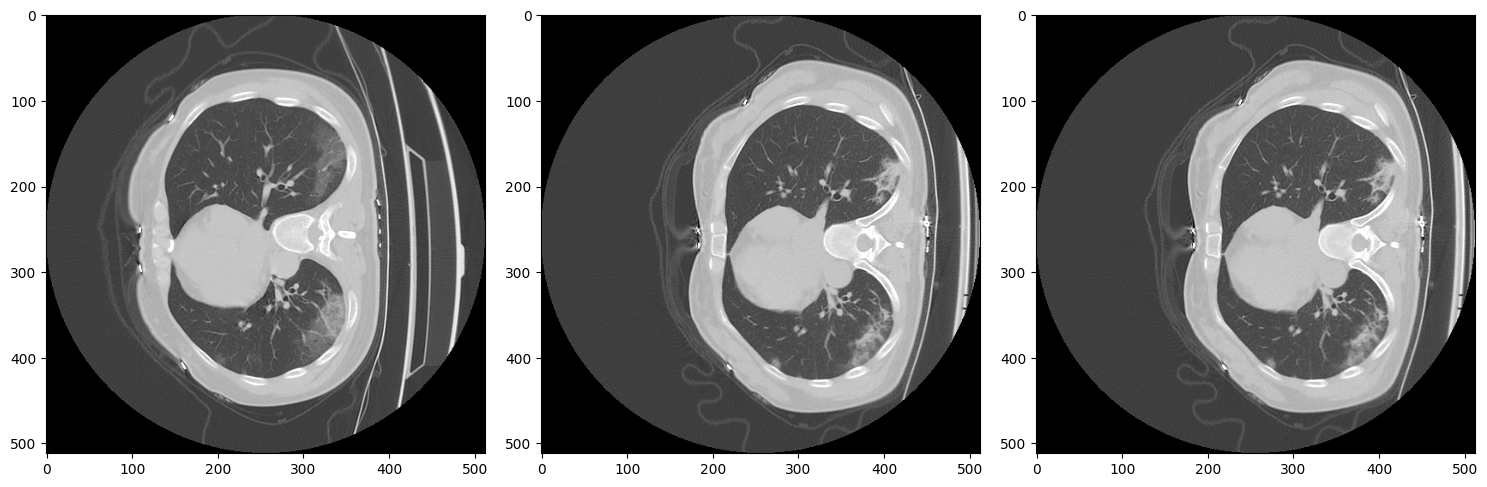

In [5]:
plt.figure(figsize=(15,5))
plt.subplot(131)
plt.imshow(ct_base[:,:,30],vmin=-1500,vmax=500,cmap='gray')
plt.subplot(132)
plt.imshow(ct_FU[:,:,30],vmin=-1500,vmax=500,cmap='gray')
plt.subplot(133)
plt.imshow(ct_FU_reg[:,:,30],vmin=-1500,vmax=500,cmap='gray')
plt.tight_layout()
plt.show()

## Exercise 1. local histogram equalization을 통해 숨겨진 패턴 확인하기

In [10]:
import numpy as np
import matplotlib.pyplot as plt

(256, 256) uint8


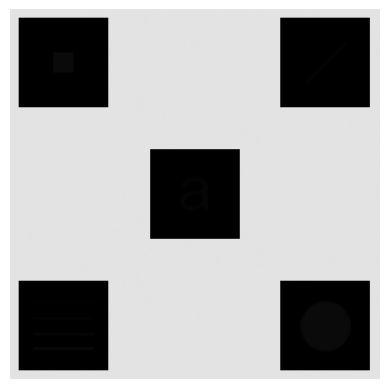

In [7]:
f = plt.imread(imgpath+'/DIP4E/hidden-symbols.tif')
print(f.shape,f.dtype)

plt.imshow(f,vmin=0,vmax=255,cmap='gray')
plt.axis('off')
plt.show()

# 위치마다 대조도 달라서 whole equalization이 안 좋을 때도 있음
# local equalization 필요(검정 네모 안)

In [8]:
def histogram_equalization(image):
    histogram, bins = np.histogram(image.flatten(), bins=256, range=[0,256])
    cdf = histogram.cumsum()
    cdf_min = cdf.min()
    cdf_max = cdf.max()
    cdf_normalized = (cdf - cdf_min) * 255 / (cdf_max - cdf_min)
    cdf_normalized = cdf_normalized.astype(np.uint8)
    equalized_image = cdf_normalized[image]
    return equalized_image

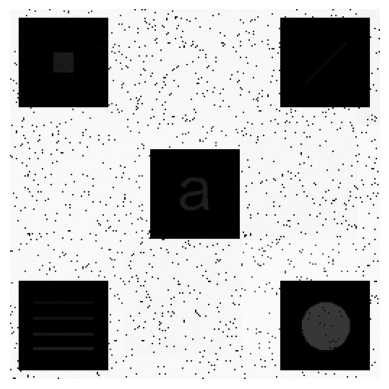

In [11]:
N = 80 # 검정색 네모의 width 결정
f_eq_local = np.zeros_like(f)
for x in np.arange(0,256,N):
  for y in np.arange(0,256,N):
    f_eq_local[x:x+N,y:y+N] = histogram_equalization(f[x:x+N,y:y+N])

plt.imshow(f_eq_local,vmin=0,vmax=255,cmap='gray')
plt.axis('off')
plt.show()

## Exercise 2. 사진을 grayscale image로 불러온 후, 서로 다른 kernel size에 대한 LPF결과 비교

In [17]:
from skimage import io
import scipy.signal as signal
import time

(191, 201) float64
computation time =  0.0035245418548583984  sec


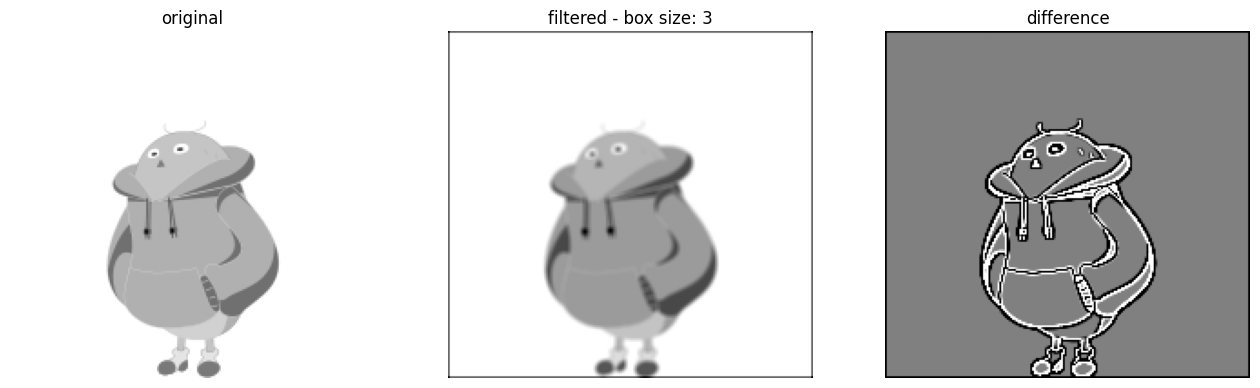

computation time =  0.024723291397094727  sec


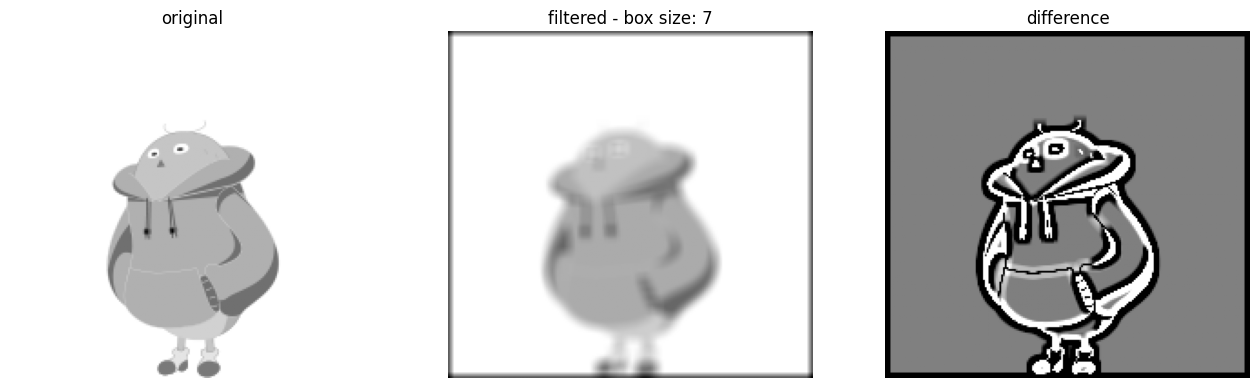

computation time =  0.08358573913574219  sec


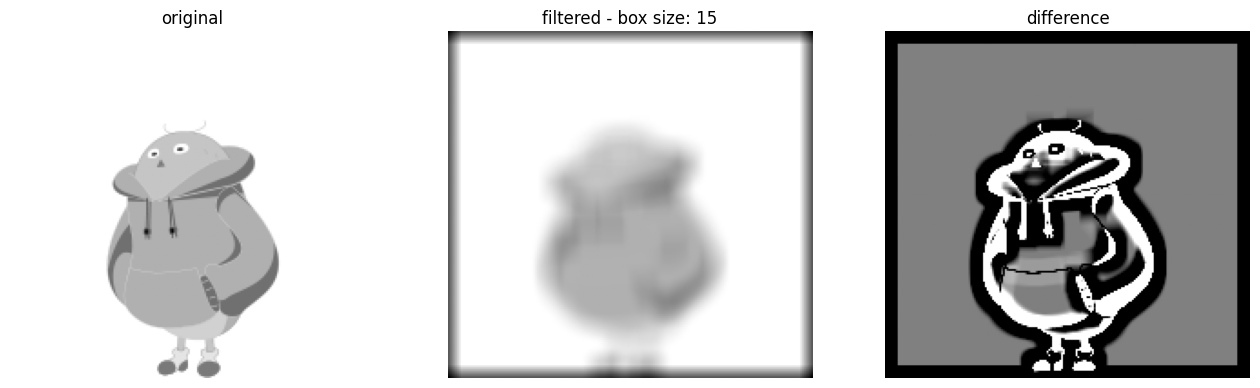

computation time =  0.06853723526000977  sec


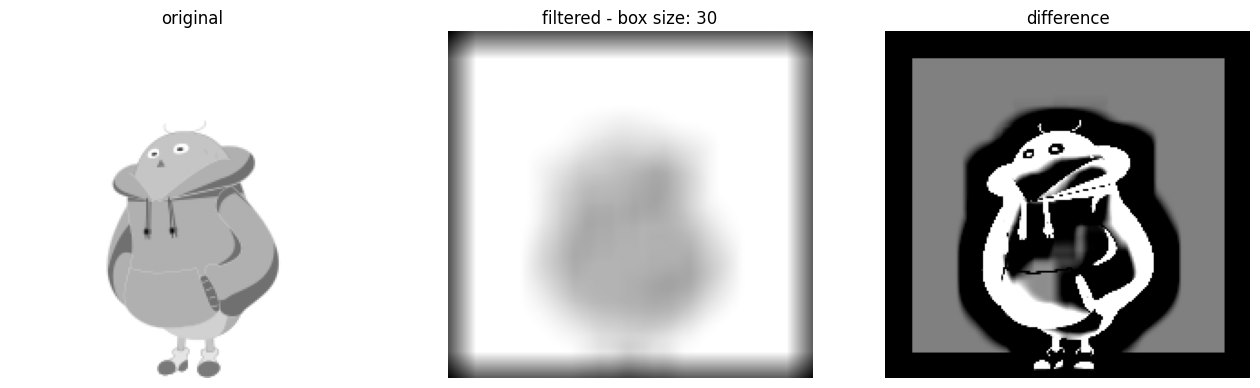

In [18]:
f = io.imread('https://www.hufs.ac.kr/sites/hufs/images/sub/img01.png',as_gray=True)
print(f.shape,f.dtype)

for N in np.array([3,7,15,30]):
  wb = np.ones((N,N))
  wb = wb/np.sum(wb)
  s0 = time.time()
  y_b = signal.convolve2d(f,wb,mode='same')
  compu_time=time.time() - s0
  print('computation time = ', compu_time,' sec')
  plt.figure(figsize=(16,9))
  plt.subplot(1,3,1)
  plt.imshow(f,cmap='gray')
  plt.axis('off')
  plt.title('original')
  plt.subplot(1,3,2)
  plt.imshow(y_b,cmap='gray')
  plt.axis('off')
  plt.title(f'filtered - box size: {N}')
  plt.subplot(1,3,3)
  plt.imshow(y_b-f,cmap='gray',vmin=-.01,vmax=.01)
  plt.axis('off')
  plt.title('difference')
  plt.show()

##  Exercise 3. Blurring이 발생한 사진을 가져와 적당한 HPF결과를 활용하여 sharpening

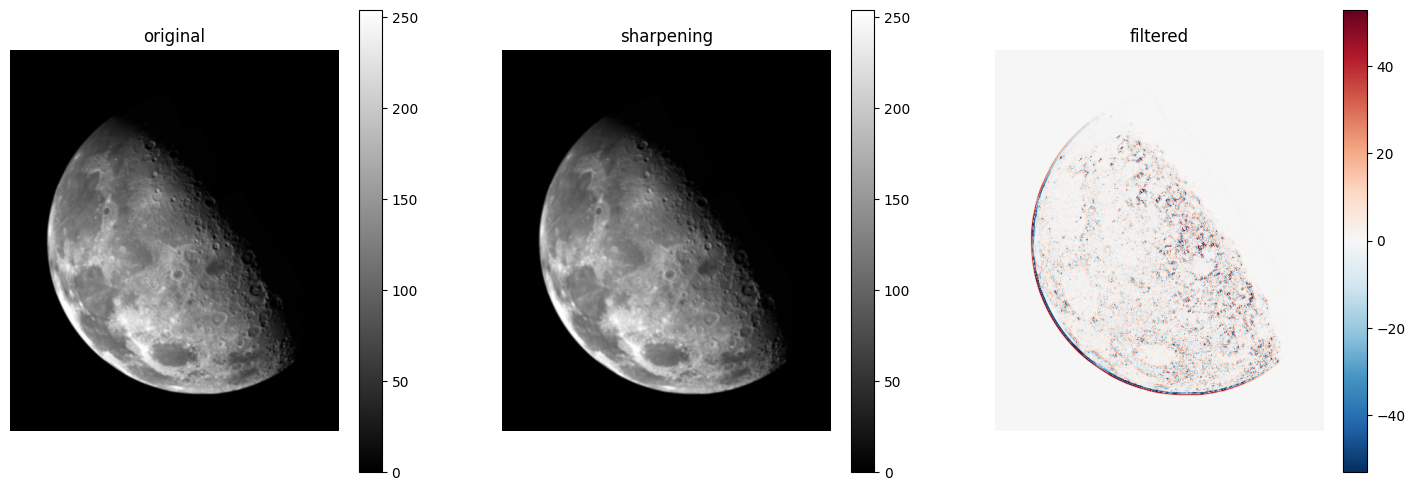

In [53]:
f = io.imread(os.path.join(imgpath + '/DIP4E/moon-blurred.tif'), as_gray=True)

w = np.array([[0,1,0],[1,-4.,1],[0,1,0]])
y = signal.convolve2d(f,w,mode='same')
c = 0.1
g = f + c*(y)
plt.figure(figsize=(18,6))
plt.subplot(131)
plt.imshow(f,cmap='gray')
plt.colorbar()
plt.axis('off')
plt.title('original')
plt.subplot(132)
plt.imshow(g,cmap='gray')
plt.colorbar()
plt.axis('off')
plt.title('sharpening')
plt.subplot(133)
plt.imshow(y,cmap='RdBu_r',vmin=-0.5*np.max(np.abs(y)),vmax=0.5*np.max(np.abs(y)))
plt.colorbar()
plt.axis('off')
plt.title('filtered')
plt.show()